In [1]:
# import libraries
import ssav_helpers
import ssav
from ssav_setup import *
from ssav_helpers import *
from ssav import *
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fftn, ifftn, fftfreq
from dataclasses import dataclass

In [5]:
L = np.array([2*np.pi, 2*np.pi])
N = np.array([128, 128])

Grid = generate_Grid(L, N, dim=2)

Time = TimeDomain(dt_min=1e-5, 
                  dt_max=0.01, 
                  t0=0, 
                  tf=5)

Para = Parameters(model="OK",
                  eps=0.02, 
                  m=0.0,
                  alpha=250000,
                  err_tol = np.array([1e-5, 1e-5]))


rng = np.random.default_rng()
u = 0.002 * rng.random((Grid.N[0], Grid.N[1])) - 0.001
u = Para.m + u - np.mean(u)

In [6]:
Results = ssav(Grid, Time, Para, u, dim=2)

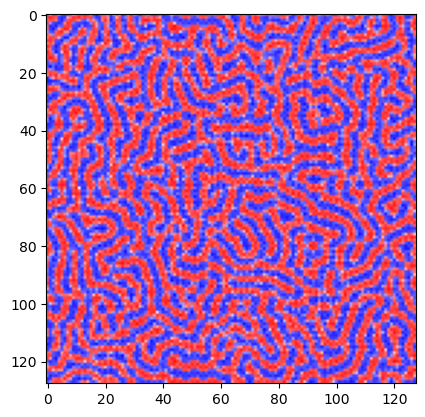

<bound method Figure.show of <Figure size 640x480 with 1 Axes>>

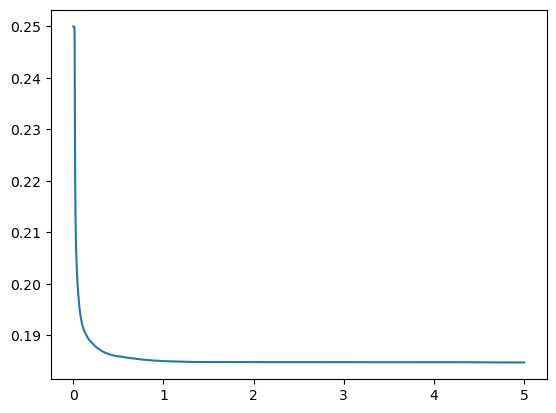

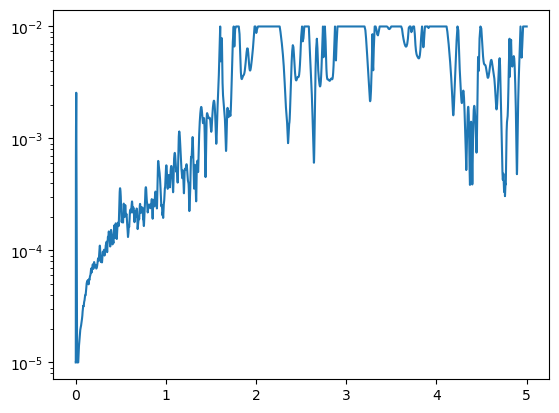

In [7]:
img = plt.imshow(Results.u, cmap = 'bwr')
img.set_clim(-1,1)

plt.colorbar
plt.show()

f1 = plt.figure()
plt.plot(Results.tt, Results.Eu)
f1.show

f2 = plt.figure()
plt.semilogy(np.array(Results.tt[1:]), Results.dt)
f2.show